In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt


In [10]:
folder_path = r"G:\My Drive\no headstage vids"
prev_file = r"ForTraining\17RR_2025_06_10_17_12_12_stitchedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120"
curr_file = r"18R\18R_2025_06_30_11_25_03_stitchedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120"

In [11]:
print(folder_path + '\\' + prev_file + ".h5")

G:\My Drive\no headstage vids\ForTraining\17RR_2025_06_10_17_12_12_stitchedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120.h5


In [12]:
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_prev_file = pd.read_hdf(folder_path + '\\' + prev_file + ".h5")
h5_curr_file = pd.read_hdf(folder_path + '\\' + curr_file + ".h5")

In [13]:
h5_curr_file

scorer    DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120  \
bodyparts                                                     nose   
coords                                                           x   
0                                                   7.488315         
1                                                   7.777886         
2                                                   7.536671         
3                                                   7.410993         
4                                                   7.614246         
...                                                      ...         
77544                                             474.856018         
77545                                             477.271088         
77546                                             481.044495         
77547                                             481.774994         
77548                                             483.485199         

scorer                                                               \
bodyparts                            midbody                          
coords              y likelihood           x           y likelihood   
0          992.001404   0.303407   33.275558  142.523743   0.433099   
1          991.618652   0.294189   33.528011  142.871521   0.422946   
2          991.916016   0.311148   33.476772  142.799011   0.426724   
3          992.055786   0.316681   33.491104  142.838318   0.425394   
4          991.820984   0.290845   33.559502  142.816833   0.427544   
...               ...        ...         ...         ...        ...   
77544      698.971924   0.618399  429.081024  707.174866   0.761768   
77545      701.304565   0.525462  434.408203  706.319641   0.917628   
77546      704.245117   0.672527  437.373016  705.286499   0.871607   
77547      706.226685   0.621763  440.195160  705.678162   0.821131   
77548      707.519653   0.654302  442.838135  705.915649   0.843843   

scorer                                                                  \
bodyparts     tailbase                               ear_R               
coords               x           y likelihood            x           y   
0            13.518434  275.254608   0.469136  1230.934082  932.431091   
1            13.458936  275.289673   0.472990  1229.705444  937.662720   
2          1131.352417   37.682228   0.463230  1229.682617  937.602661   
3            13.631626  274.874054   0.457493  1229.805908  937.543701   
4          1130.845947   37.377689   0.495043  1229.729004  937.585022   
...                ...         ...        ...          ...         ...   
77544       398.884277  707.687439   0.636862   459.580811  710.078125   
77545      1008.447571   21.392534   0.579608   463.772308  710.548889   
77546      1008.433838   21.303625   0.583089   466.408722  710.974243   
77547       410.990234  706.564697   0.650622   467.797333  711.881042   
77548       413.477051  705.392395   0.639792   469.238281  712.514771   

scorer                                                    
bodyparts                   ear_L                         
coords    likelihood            x           y likelihood  
0           0.371297  1245.637573  940.105164   0.267320  
1           0.280459  1245.890991  940.448120   0.232109  
2           0.287565  1245.779053  940.553162   0.237785  
3           0.285610  1245.842896  940.433167   0.228468  
4           0.297318  1245.751343  940.576172   0.238390  
...              ...          ...         ...        ...  
77544       0.604517   457.026184  697.230957   0.590487  
77545       0.569700   463.153320  698.239563   0.593893  
77546       0.756703   466.448578  697.515137   0.763159  
77547       0.719557   468.424164  698.707092   0.688539  
77548       0.746611   471.136322  698.983765   0.745771  

[77549 rows x 15 columns]

In [14]:
# Update to be the actual file name according to the first index column value of the h5 table
prev_file_name = 'DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120'
curr_file_name = 'DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120'

# Load the DataFrame from the HDF5 file
dlc_raw_prev_h5 = h5_prev_file[prev_file_name]
dlc_raw_curr_h5 = h5_curr_file[curr_file_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_prev_h5.iloc[0], dlc_raw_prev_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_prev_h5 = dlc_raw_prev_h5.apply(pd.to_numeric, errors='coerce')
dlc_raw_curr_h5 = dlc_raw_curr_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

prev_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_prev_h5)), columns=new_index)
curr_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_curr_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_prev_h5 = pd.concat([dlc_raw_prev_h5, prev_new_index_df], axis=1)
dlc_raw_curr_h5 = pd.concat([dlc_raw_curr_h5, curr_new_index_df], axis=1)

dlc_raw_prev_h5


nose                             midbody              \
                  x           y likelihood            x           y   
0         10.843078   14.950644   0.257409  1119.190674   18.017811   
1          5.586076  993.061829   0.241072  1117.906128   19.634327   
2          5.714989  993.006653   0.248210  1119.476929   24.130724   
3       1239.233032  951.102722   0.280466  1119.224609   24.579016   
4       1239.343506  951.009033   0.274686  1118.904297   24.771227   
...             ...         ...        ...          ...         ...   
137400   150.168198  101.893822   0.878733   151.678253  141.850998   
137401   150.676422  102.331467   0.889701   151.121414  142.172104   
137402   150.794983  102.179039   0.888246   151.102188  142.130066   
137403   150.962296  102.196167   0.884047   151.499069  141.830200   
137404   150.940811  102.120522   0.883586   151.194412  141.697418   

                      tailbase                               ear_R  \
       likelihood            x           y likelihood            x   
0        0.433045  1090.039673   33.308159   0.343204  1236.286743   
1        0.428461  1089.898926   34.546143   0.384348  1235.609253   
2        0.424686  1089.931396   34.843269   0.437693  1235.156860   
3        0.359338  1090.625244   34.283810   0.374207  1234.567871   
4        0.373868  1089.799438   33.717999   0.387141  1234.840088   
...           ...          ...         ...        ...          ...   
137400   0.823441   155.151825  156.859558   0.507348   157.742035   
137401   0.828543   155.203323  156.992722   0.498935   157.724274   
137402   0.833226   155.135651  157.041245   0.502244   157.762894   
137403   0.845888   154.921249  156.729568   0.512105   158.059235   
137404   0.841184   154.681213  156.717178   0.506170   157.969742   

                                     ear_L                        weighted  \
                 y likelihood            x           y likelihood        x   
0       933.419434   0.350672     7.102080   21.112576   0.322542      NaN   
1       933.546997   0.283933  1240.661865  923.637329   0.254943      NaN   
2       933.933289   0.323426  1241.001953  924.563965   0.274478      NaN   
3       933.541687   0.399236  1241.179810  924.203979   0.313362      NaN   
4       933.512085   0.379906  1241.004761  924.282715   0.311910      NaN   
...            ...        ...          ...         ...        ...      ...   
137400  121.993652   0.777469   143.751892  120.669624   0.741911      NaN   
137401  122.232513   0.780067   143.502853  120.669800   0.759518      NaN   
137402  122.155487   0.769389   143.473938  120.432556   0.758469      NaN   
137403  121.965210   0.773754   144.108490  120.314384   0.752252      NaN   
137404  121.812172   0.776637   143.883698  120.122810   0.750811      NaN   

                       
         y likelihood  
0      NaN        NaN  
1      NaN        NaN  
2      NaN        NaN  
3      NaN        NaN  
4      NaN        NaN  
...     ..        ...  
137400 NaN        NaN  
137401 NaN        NaN  
137402 NaN        NaN  
137403 NaN        NaN  
137404 NaN        NaN  

[137405 rows x 18 columns]

In [15]:
dlc_raw_curr_h5

nose                            midbody                         \
                x           y likelihood           x           y likelihood   
0        7.488315  992.001404   0.303407   33.275558  142.523743   0.433099   
1        7.777886  991.618652   0.294189   33.528011  142.871521   0.422946   
2        7.536671  991.916016   0.311148   33.476772  142.799011   0.426724   
3        7.410993  992.055786   0.316681   33.491104  142.838318   0.425394   
4        7.614246  991.820984   0.290845   33.559502  142.816833   0.427544   
...           ...         ...        ...         ...         ...        ...   
77544  474.856018  698.971924   0.618399  429.081024  707.174866   0.761768   
77545  477.271088  701.304565   0.525462  434.408203  706.319641   0.917628   
77546  481.044495  704.245117   0.672527  437.373016  705.286499   0.871607   
77547  481.774994  706.226685   0.621763  440.195160  705.678162   0.821131   
77548  483.485199  707.519653   0.654302  442.838135  705.915649   0.843843   

          tailbase                               ear_R                         \
                 x           y likelihood            x           y likelihood   
0        13.518434  275.254608   0.469136  1230.934082  932.431091   0.371297   
1        13.458936  275.289673   0.472990  1229.705444  937.662720   0.280459   
2      1131.352417   37.682228   0.463230  1229.682617  937.602661   0.287565   
3        13.631626  274.874054   0.457493  1229.805908  937.543701   0.285610   
4      1130.845947   37.377689   0.495043  1229.729004  937.585022   0.297318   
...            ...         ...        ...          ...         ...        ...   
77544   398.884277  707.687439   0.636862   459.580811  710.078125   0.604517   
77545  1008.447571   21.392534   0.579608   463.772308  710.548889   0.569700   
77546  1008.433838   21.303625   0.583089   466.408722  710.974243   0.756703   
77547   410.990234  706.564697   0.650622   467.797333  711.881042   0.719557   
77548   413.477051  705.392395   0.639792   469.238281  712.514771   0.746611   

             ear_L                        weighted                 
                 x           y likelihood        x   y likelihood  
0      1245.637573  940.105164   0.267320      NaN NaN        NaN  
1      1245.890991  940.448120   0.232109      NaN NaN        NaN  
2      1245.779053  940.553162   0.237785      NaN NaN        NaN  
3      1245.842896  940.433167   0.228468      NaN NaN        NaN  
4      1245.751343  940.576172   0.238390      NaN NaN        NaN  
...            ...         ...        ...      ...  ..        ...  
77544   457.026184  697.230957   0.590487      NaN NaN        NaN  
77545   463.153320  698.239563   0.593893      NaN NaN        NaN  
77546   466.448578  697.515137   0.763159      NaN NaN        NaN  
77547   468.424164  698.707092   0.688539      NaN NaN        NaN  
77548   471.136322  698.983765   0.745771      NaN NaN        NaN  

[77549 rows x 18 columns]

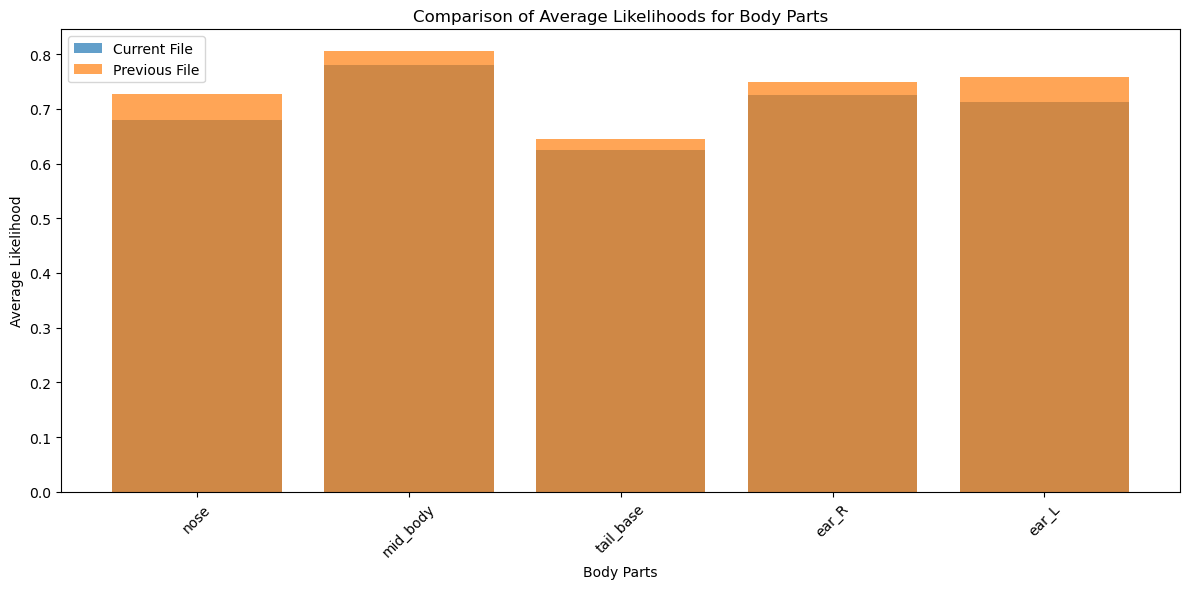

In [16]:
# Extract likelihood columns for both datasets
curr_likelihoods = dlc_raw_curr_h5.xs('likelihood', level=1, axis=1)
prev_likelihoods = dlc_raw_prev_h5.xs('likelihood', level=1, axis=1)

# Drop the 'weighted' column from both datasets
curr_likelihoods = curr_likelihoods.drop(columns=['weighted'])
prev_likelihoods = prev_likelihoods.drop(columns=['weighted'])

# Rename columns to merge names with '_'
curr_likelihoods.columns = curr_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
prev_likelihoods.columns = prev_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
# Calculate average likelihoods for each body part
curr_avg_likelihoods = curr_likelihoods.mean()
prev_avg_likelihoods = prev_likelihoods.mean()

# Plot the average likelihoods for comparison
plt.figure(figsize=(12, 6))
plt.bar(curr_avg_likelihoods.index, curr_avg_likelihoods, alpha=0.7, label='Current File')
plt.bar(prev_avg_likelihoods.index, prev_avg_likelihoods, alpha=0.7, label='Previous File')
plt.xlabel('Body Parts')
plt.ylabel('Average Likelihood')
plt.title('Comparison of Average Likelihoods for Body Parts')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

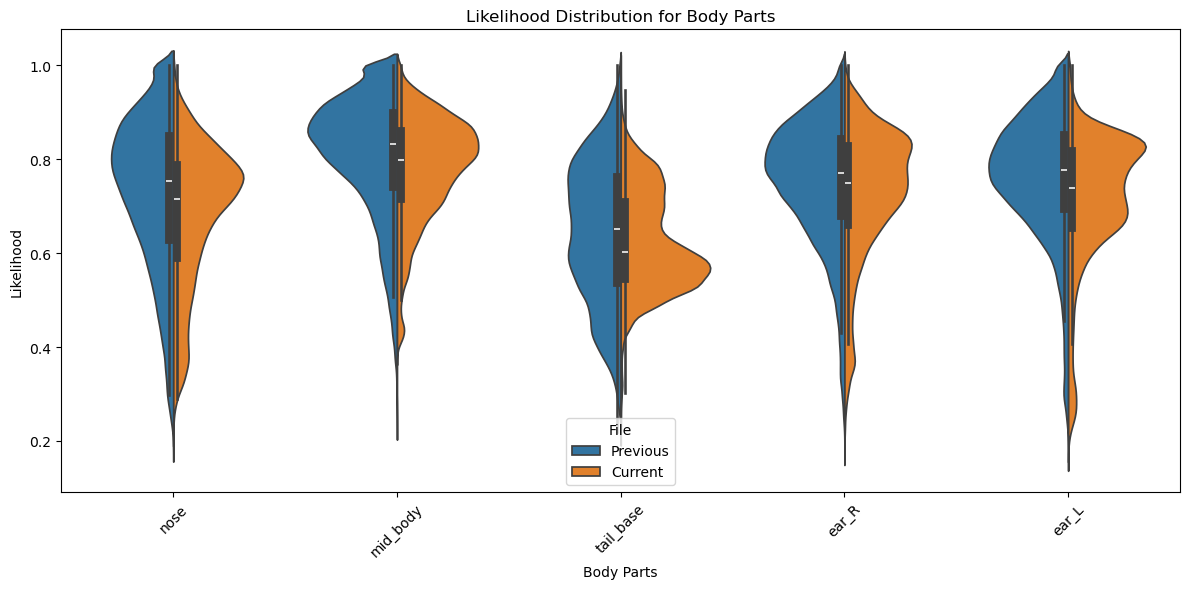

In [17]:
import seaborn as sns

# Combine the likelihood data into a single DataFrame for plotting
combined_likelihoods = pd.concat([
    prev_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Previous'),
    curr_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Current')
])

# Create the violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=combined_likelihoods, x='Body Part', y='Likelihood', hue='File', split=True)
plt.title('Likelihood Distribution for Body Parts')
plt.xlabel('Body Parts')
plt.ylabel('Likelihood')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from itertools import combinations

# Define bodyparts to check
bodyparts = ['nose', 'midbody', 'tailbase', 'ear_R', 'ear_L']

# 1. Inter-bodypart distance outlier detection
# Calculate average distance between each pair of bodyparts across all frames

# Get coordinates for each bodypart
coords = {bp: np.stack([dlc_raw_curr_h5[(bp, 'x')], dlc_raw_curr_h5[(bp, 'y')]], axis=1) for bp in bodyparts}

# Compute mean distance for each pair
pairwise_means = {}
pairwise_medians = {}
for bp1, bp2 in combinations(bodyparts, 2):
    dists = np.linalg.norm(coords[bp1] - coords[bp2], axis=1)
    pairwise_means[(bp1, bp2)] = dists.mean()
    pairwise_medians[(bp1, bp2)] = dists.median()  # Using median for more robust outlier detection

# For each frame, check if any pair is > 3x median distance
outlier_matrix_dist = pd.DataFrame(False, index=dlc_raw_curr_h5.index, columns=bodyparts)
for bp1, bp2 in combinations(bodyparts, 2):
    dists = np.linalg.norm(coords[bp1] - coords[bp2], axis=1)
    outlier_frames = dists > 3 * pairwise_medians[(bp1, bp2)]
    # Mark both bodyparts as outlier in these frames
    outlier_matrix_dist.loc[outlier_frames, bp1] = True
    outlier_matrix_dist.loc[outlier_frames, bp2] = True

# 2. Jump outlier detection (frame-to-frame movement)
outlier_matrix_jump = pd.DataFrame(False, index=dlc_raw_curr_h5.index, columns=bodyparts)
for bp in bodyparts:
    xy = coords[bp]
    jumps = np.linalg.norm(xy[1:] - xy[:-1], axis=1)
    mean_jump = jumps.mean()
    perc90_jump = np.percentile(jumps, 95)
    median_jump = np.median(jumps)
    max_jump = jumps.max()
    # Outlier if jump > 3 times median jump
    outlier_idx = np.where(jumps > median_jump * 3)[0] + 1  # +1 because jump is from frame i-1 to i
    outlier_matrix_jump.loc[outlier_idx, bp] = True

# Combine both outlier matrices
outlier_matrix = outlier_matrix_dist | outlier_matrix_jump

# Show summary of outliers per bodypart
outlier_counts = outlier_matrix.sum()
print("Outlier counts per bodypart:")
print(outlier_counts)

# Optionally, show frames with any outlier
outlier_frames = outlier_matrix.any(axis=1)
print(f"Total frames with any outlier: {outlier_frames.sum()}")

print("Total frames in dataset:", len(dlc_raw_curr_h5))

# outlier_matrix is a DataFrame (frames x bodyparts) with True for outlier labels

Outlier counts per bodypart:
nose        44551
midbody     44731
tailbase    53164
ear_R       44349
ear_L       43764
dtype: int64
Total frames with any outlier: 56455
Total frames in dataset: 77549


In [127]:
# Create a DataFrame with only the frames that are outliers
outlier_frames_df = dlc_raw_curr_h5[outlier_frames].copy()
# Add a column with the original index
outlier_frames_df['original_index'] = outlier_frames_df.index
outlier_frames_df

nose                            midbody                         \
                x           y likelihood           x           y likelihood   
0        7.488315  992.001404   0.303407   33.275558  142.523743   0.433099   
1        7.777886  991.618652   0.294189   33.528011  142.871521   0.422946   
2        7.536671  991.916016   0.311148   33.476772  142.799011   0.426724   
3        7.410993  992.055786   0.316681   33.491104  142.838318   0.425394   
4        7.614246  991.820984   0.290845   33.559502  142.816833   0.427544   
...           ...         ...        ...         ...         ...        ...   
77544  474.856018  698.971924   0.618399  429.081024  707.174866   0.761768   
77545  477.271088  701.304565   0.525462  434.408203  706.319641   0.917628   
77546  481.044495  704.245117   0.672527  437.373016  705.286499   0.871607   
77547  481.774994  706.226685   0.621763  440.195160  705.678162   0.821131   
77548  483.485199  707.519653   0.654302  442.838135  705.915649   0.843843   

          tailbase                               ear_R                         \
                 x           y likelihood            x           y likelihood   
0        13.518434  275.254608   0.469136  1230.934082  932.431091   0.371297   
1        13.458936  275.289673   0.472990  1229.705444  937.662720   0.280459   
2      1131.352417   37.682228   0.463230  1229.682617  937.602661   0.287565   
3        13.631626  274.874054   0.457493  1229.805908  937.543701   0.285610   
4      1130.845947   37.377689   0.495043  1229.729004  937.585022   0.297318   
...            ...         ...        ...          ...         ...        ...   
77544   398.884277  707.687439   0.636862   459.580811  710.078125   0.604517   
77545  1008.447571   21.392534   0.579608   463.772308  710.548889   0.569700   
77546  1008.433838   21.303625   0.583089   466.408722  710.974243   0.756703   
77547   410.990234  706.564697   0.650622   467.797333  711.881042   0.719557   
77548   413.477051  705.392395   0.639792   469.238281  712.514771   0.746611   

             ear_L                        weighted                 \
                 x           y likelihood        x   y likelihood   
0      1245.637573  940.105164   0.267320      NaN NaN        NaN   
1      1245.890991  940.448120   0.232109      NaN NaN        NaN   
2      1245.779053  940.553162   0.237785      NaN NaN        NaN   
3      1245.842896  940.433167   0.228468      NaN NaN        NaN   
4      1245.751343  940.576172   0.238390      NaN NaN        NaN   
...            ...         ...        ...      ...  ..        ...   
77544   457.026184  697.230957   0.590487      NaN NaN        NaN   
77545   463.153320  698.239563   0.593893      NaN NaN        NaN   
77546   466.448578  697.515137   0.763159      NaN NaN        NaN   
77547   468.424164  698.707092   0.688539      NaN NaN        NaN   
77548   471.136322  698.983765   0.745771      NaN NaN        NaN   

      original_index  
                      
0                  0  
1                  1  
2                  2  
3                  3  
4                  4  
...              ...  
77544          77544  
77545          77545  
77546          77546  
77547          77547  
77548          77548  

[56455 rows x 19 columns]

In [84]:
from collections import Counter

# Find sequences of consecutive frames with any outlier
outlier_bool = outlier_frames.values  # Convert to numpy array for efficient processing

# Find the start and end indices of each sequence
diff = np.diff(outlier_bool.astype(int))
starts = np.where(diff == 1)[0] + 1 if outlier_bool[0] == False else np.insert(np.where(diff == 1)[0] + 1, 0, 0)
ends = np.where(diff == -1)[0] + 1 if outlier_bool[-1] == False else np.append(np.where(diff == -1)[0] + 1, len(outlier_bool))

# If the first frame is an outlier, ensure the first sequence starts at 0
if outlier_bool[0]:
    starts = np.insert(starts, 0, 0)
# If the last frame is an outlier, ensure the last sequence ends at the last index
if outlier_bool[-1]:
    ends = np.append(ends, len(outlier_bool))

# Calculate sequence lengths
seq_lengths = ends - starts

# Count the number of sequences for each length
length_counts = Counter(seq_lengths)

# Convert to DataFrame for easier viewing (optional)
seq_length_df = pd.DataFrame.from_dict(length_counts, orient='index', columns=['count']).sort_index()
seq_length_df.index.name = 'sequence_length'
seq_length_df

,count
sequence_length,
3,195
4,214
5,261
6,213
7,170
...,...
716,1
798,1
885,1


In [63]:
outlier_matrix_dist.sum()

nose        33824
midbody     34281
tailbase    34277
ear_R       34251
ear_L       34273
dtype: int64

In [60]:
outlier_matrix_jump.sum()

nose        17408
midbody     17372
tailbase    25769
ear_R       16698
ear_L       15624
dtype: int64

In [53]:
perc90_jump

7.589806151390073

In [37]:
mean_jump

14.42465

In [57]:
median_jump

1.2471712

In [54]:
pairwise_means

{('nose', 'midbody'): 122.97814,
 ('nose', 'tailbase'): 419.60416,
 ('nose', 'ear_R'): 56.670544,
 ('nose', 'ear_L'): 61.768192,
 ('midbody', 'tailbase'): 353.39136,
 ('midbody', 'ear_R'): 88.81614,
 ('midbody', 'ear_L'): 78.21126,
 ('tailbase', 'ear_R'): 395.91968,
 ('tailbase', 'ear_L'): 389.17435,
 ('ear_R', 'ear_L'): 31.638271}

In [55]:
pairwise_medians

{('nose', 'midbody'): 41.597404,
 ('nose', 'tailbase'): 76.50423,
 ('nose', 'ear_R'): 19.494696,
 ('nose', 'ear_L'): 19.312119,
 ('midbody', 'tailbase'): 28.942162,
 ('midbody', 'ear_R'): 25.3327,
 ('midbody', 'ear_L'): 24.46187,
 ('tailbase', 'ear_R'): 59.46163,
 ('tailbase', 'ear_L'): 58.10659,
 ('ear_R', 'ear_L'): 14.035453}

C:\Users\Almog\AppData\Local\Temp\ipykernel_3057184\766892856.py:12: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  outlier_idx = int(outlier_frames_df.iloc[28200]['original_index'])


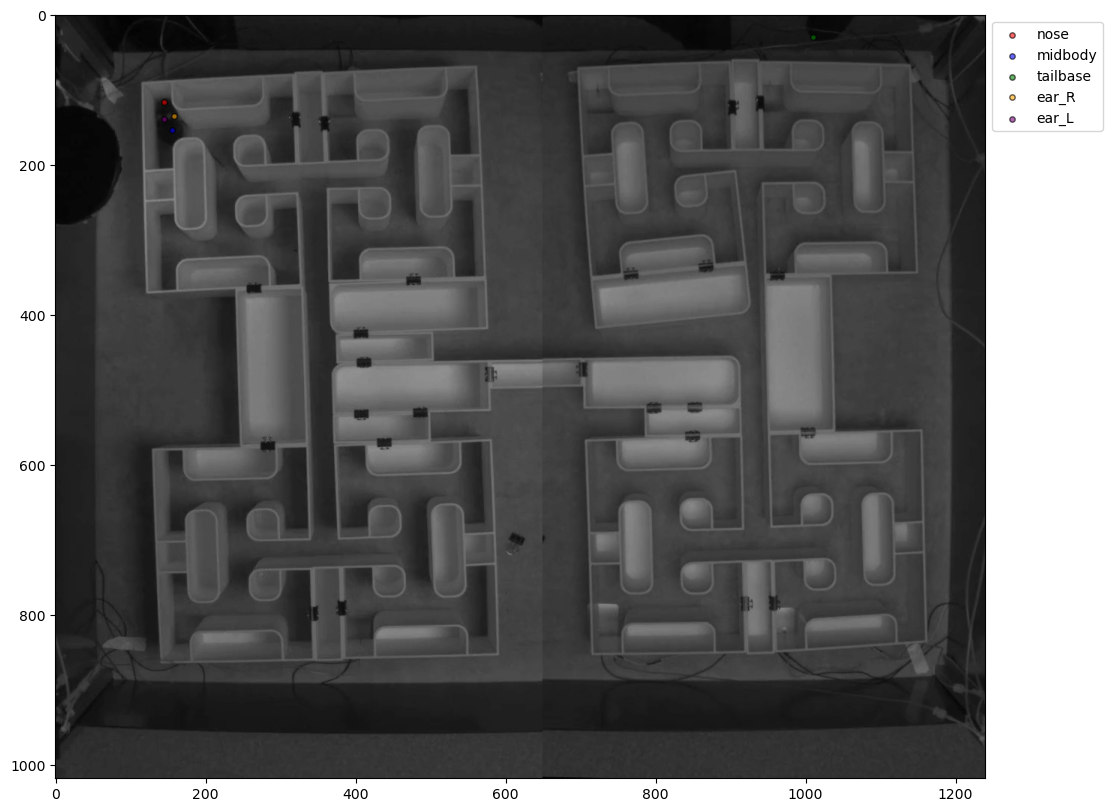

In [150]:
import cv2
# Prepare color map for bodyparts
color_map = {
    'nose': 'red',
    'midbody': 'blue',
    'tailbase': 'green',
    'ear_R': 'orange',
    'ear_L': 'purple'
}

# Find the n frame index with any outlier in the dist matrix
outlier_idx = int(outlier_frames_df.iloc[28200]['original_index'])
# outlier_idx = 36778

# Read the video file (assume video file is in the same folder and named after curr_file, with .mp4 extension)
video_path = r"G:\My Drive\no headstage vids\18R\18R_2025_06_30_11_25_03_stitched.mp4"
cap = cv2.VideoCapture(video_path)

# Get the frame at outlier_idx (assuming outlier_idx matches video frame index)
cap.set(cv2.CAP_PROP_POS_FRAMES, outlier_idx)
ret, frame_img = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f"Could not read frame {outlier_idx} from {video_path}")

# Convert BGR (OpenCV) to RGB (matplotlib)
frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)
# Remove bodypart text, only plot colored dots.
# Collect handles and labels for legend (only for outlier bodyparts)
handles = []
labels = []

plt.figure(figsize=(12, 12))
plt.imshow(frame_img)
for bp in bodyparts:
    x = dlc_raw_curr_h5.loc[outlier_idx, (bp, 'x')]
    y = dlc_raw_curr_h5.loc[outlier_idx, (bp, 'y')]
    is_out = outlier_matrix_dist.loc[outlier_idx, bp]
    sc = plt.scatter(x, y, color=color_map[bp], marker='.', label=bp if is_out else None, 
                     s=60, edgecolor='black' if is_out else None, alpha=0.6)
    if is_out:
        handles.append(sc)
        labels.append(bp)

plt.legend(handles, labels, loc='upper left', bbox_to_anchor=(1, 1))


In [145]:
outlier_frames_df.iloc[25200]['original_index']

    36779.0
Name: 36779, dtype: float64